# Sinusoidal Regression

## Imports

In [2]:
import os
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import curve_fit

## Load Data

In [3]:
base_dir = os.path.join(os.getcwd(), '..')
processed_data_dir = os.path.join(base_dir, 'processed_data')

open_meteo_filepath = os.path.join(processed_data_dir, 'open_meteo_processed_data.csv')
open_meteo_df = pd.read_csv(open_meteo_filepath, parse_dates=['datetime'])

ausgrid_filepath = os.path.join(processed_data_dir, 'ausgrid_processed_data.csv')
ausgrid_df = pd.read_csv(ausgrid_filepath, parse_dates=['datetime'])

## Initial Scatterplot

First, we create a scatterplot of irradiance versus the time of day. We use `alpha=0.03` to make the points transparent. Besause the data has a 30-minute time-resolution, the time of day variable exists in discrete 30-minute bins. For each time of day, more common irradiance values appear darker, as more transparent points overlap.

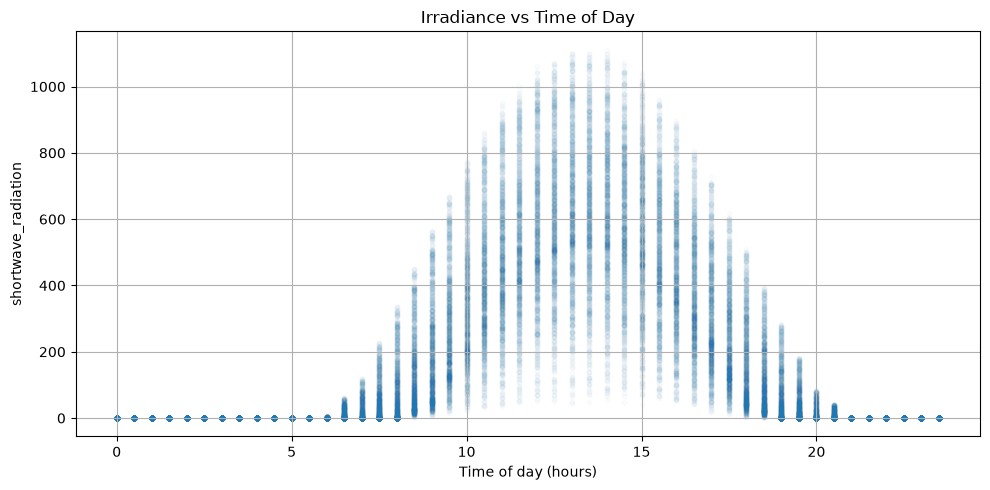

In [4]:
# construct numerical time of day column
open_meteo_df["time_of_day"] = (
    open_meteo_df["datetime"].dt.hour
    + open_meteo_df["datetime"].dt.minute / 60
    + open_meteo_df["datetime"].dt.second / 3600)

plt.figure(figsize=(10, 5))
plt.scatter(open_meteo_df["time_of_day"], open_meteo_df['shortwave_radiation'], alpha=0.02, s=10)
plt.xlabel("Time of day (hours)")
plt.ylabel('shortwave_radiation')
plt.title(f"Irradiance vs Time of Day")
plt.grid(True)
plt.tight_layout()
plt.show()

## Sinusoidal Line-of-best fit
- Source: [(https://www.geeksforgeeks.org/data-analysis/fitting-a-sine-curve-to-data-with-pylab-and-numpy/)]

Useful in any domain where periodic behavior is observed. The general form is:

$y = A \times \sin (Bx + C) + D$
- A = Amplitude
- B = Frequency
- C = Phase Shift
- D = Vertical offset

In [5]:
def sine_function(x, A, B, C, D): return A * np.sin(B * x + C) + D

Fitted parameters: A=311.0294634184605, B=0.33479205140003276, C=-2.8603820559892865, D=239.6188376356625


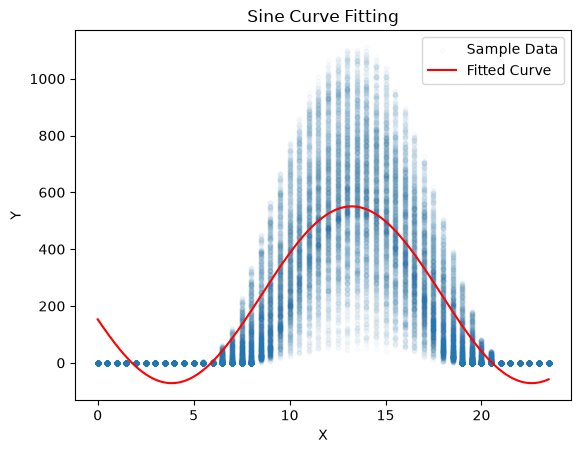

In [6]:
x = open_meteo_df['time_of_day']
y = open_meteo_df['shortwave_radiation']
initial_guess = [550, 2*np.pi/24, -1.96, 550]

params, covariance = curve_fit(sine_function, x, y, p0=initial_guess)
A_fit, B_fit, C_fit, D_fit = params

print(f"Fitted parameters: A={A_fit}, B={B_fit}, C={C_fit}, D={D_fit}")

# Generate Line-of-Best-Fit
x_fit = np.linspace(x.min(), x.max(), 500)
y_fit = sine_function(x_fit, *params)

# Plot the original data and the fitted curve
plt.scatter(x, y, label='Sample Data', alpha=0.02, s=10)
plt.plot(x_fit, y_fit, label='Fitted Curve', color='red')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Sine Curve Fitting')
plt.legend()
plt.show()

As we can see, the line-of-best-fit does a decent job of describing all of the data, tending towards the middle of the spread. However, the line of best fit is a bit 'wider' than we would expect, meaning the frequency parameter is a bit off. It seems possible that the zero values are misleading the line of best fit. This makes sense because an oridinary sine function only has two points at the zero crossing per period, but this irradiance data has many zero points. Irradiance is near zero for a long stretch overnight, when a real sine wave only crosses zero twice per cycle. 

Ideas to try: fit a daylight-shaped curve instead: Use a half-sine that is constrained to zero outside sunrise and sunset.

## Daylight Shaped Curve

The daylight half-sine models irradiance as zero overnight, and as a positive arch between sunrise and sunset. It has three parameters: `A` (amplitude), `sunrise`, and `sunset`. The fraction inside `sin` maps the time from sunrise-to-sunset onto angles from 0 to $\pi$.

In [7]:
def daylight_curve(x, A, sunrise, sunset):
    y = np.zeros_like(x, dtype=float)
    daylight = (x >= sunrise) & (x <= sunset)
    y[daylight] = A * np.sin(np.pi * (x[daylight] - sunrise) / (sunset - sunrise))
    return y

Next we fit the parameters with `curve_fit`.

Fitted parameters: A=602.0342026638638, Sunrise=7.613333044274462, Sunset=19.161063987477327


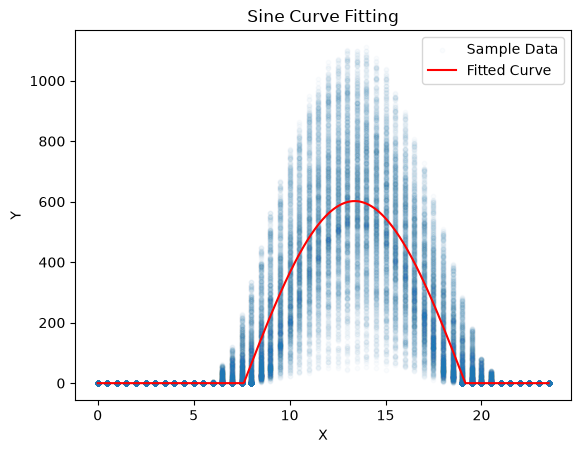

In [8]:
initial_guess = [600, 6.5, 20.5]
params, covariance = curve_fit(daylight_curve, x, y, p0=initial_guess)

A_fit, sunrise_fit, sunset_fit = params
print(f"Fitted parameters: A={A_fit}, Sunrise={sunrise_fit}, Sunset={sunset_fit}")

# Generate Line-of-Best-Fit
x_fit = np.linspace(x.min(), x.max(), 500)
y_fit = daylight_curve(x_fit, *params)

# Plot the original data and the fitted curve
plt.scatter(x, y, label='Sample Data', alpha=0.02, s=10)
plt.plot(x_fit, y_fit, label='Fitted Curve', color='red')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Sine Curve Fitting')
plt.legend()
plt.show()

Next up, let's apply similar sinusoidal regression to PV output power, and see the results.

## Sinusoidal Regression PV Output Power

Fitted parameters: A=0.984970920039601, Sunrise=7.742565174748746, Sunset=18.25742623298949


c:\Users\codett\anaconda3\envs\Energy-Disaggregation\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


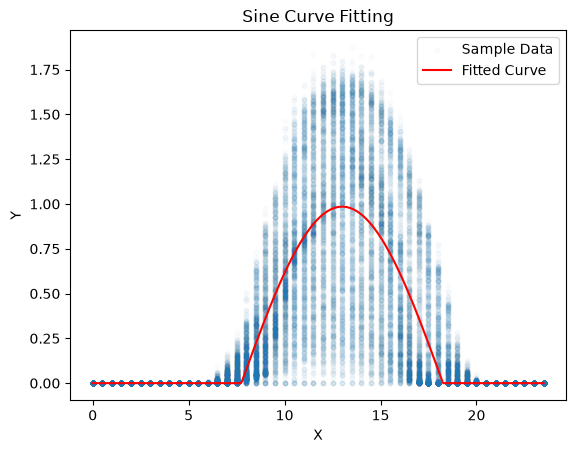

In [9]:
# construct numerical time of day column
ausgrid_df['time_of_day'] = (
    open_meteo_df["datetime"].dt.hour
    + open_meteo_df["datetime"].dt.minute / 60
    + open_meteo_df["datetime"].dt.second / 3600)

x = ausgrid_df['time_of_day']
y = ausgrid_df['Pgen']

initial_guess = [600, 6.5, 20.5] # revise this
params, covariance = curve_fit(daylight_curve, x, y, p0=initial_guess)

A_fit, sunrise_fit, sunset_fit = params
print(f"Fitted parameters: A={A_fit}, Sunrise={sunrise_fit}, Sunset={sunset_fit}")

# Generate Line-of-Best-Fit
x_fit = np.linspace(x.min(), x.max(), 500)
y_fit = daylight_curve(x_fit, *params)

# Plot the original data and the fitted curve
plt.scatter(x, y, label='Sample Data', alpha=0.02, s=10)
plt.plot(x_fit, y_fit, label='Fitted Curve', color='red')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('Sine Curve Fitting')
plt.legend()
plt.show()

For the irradiance best-fit curve, we estimated the `sunrise` as 7.61 and `sunset` as 19.16. For the PV generation curve-of-best fit, we estimated `sunrise` as 7.74 and `sunset` as `18.26`. This means that the PV generation curve resembles a daylight curve when sunrise is slightly later, and sunset is significantly (hearly an hour) earlier. This is not because sunrise and sunset are actually different.

Theoretically, if a PV array had perfect efficiency, its generation curve should have the exact same shape (except for amplitude) as the irradiance curve. However, the PV array efficiency depends on both irradiance and temperature.

## Parameter Correction

We can try to learn a mapping from the irradiance curve parameters to the PV generation curve parameters using our historical data. This lets us preserve the sinusoidal regression model while accounting for the fact that PV generation typically starts later, ends earilier, and scales differently than irradiance. 

### 1. Simple parameter correction
The sinusoidal regression produces three parameters for each day:
- **Irradiance**: Sunrise $s_I$, sunset $e_I$, amplitude $A_I$
- **PV Generation**: Sunrise $s_P$, sunset $e_P$, amplitude $A_P$

For each historical day, calculate the differences between the fitted parameters:

$ \delta_s = s_P - s_I $

$ \delta_e = e_I - e_P $

$ r_A = \frac{A_P}{A_I} $

Then, for a new day, we calculate the irradiance parameters first from the historical data. Then, we apply the corrections to obtain the new PV generation curve parameters:

$ \hat{s}_P = s_I + \delta_S $

$ \hat{e}_P = e_I - \delta_e $

$ \hat{A}_P = A_I \times r_A $

First, lets pick an example customer, and calculate the irradiance and PV generation curve parameters separately for every day.

In [15]:
customer_id = 1
customer_df = ausgrid_df[ausgrid_df["Customer"] == customer_id].copy()

# Randomly split dates, keeping each day's observations together.
customer_df["date"] = customer_df["datetime"].dt.normalize()
dates = customer_df["date"].drop_duplicates().to_numpy()

rng = np.random.default_rng(42)
shuffled_dates = rng.permutation(dates)
split_idx = int(0.8 * len(shuffled_dates))

train_dates = shuffled_dates[:split_idx]
test_dates = shuffled_dates[split_idx:]

customer_train_df = customer_df[customer_df["date"].isin(train_dates)].copy()
customer_test_df = customer_df[customer_df["date"].isin(test_dates)].copy()

daily_rows = []

for day in train_dates:
    ir_day = open_meteo_df[
        open_meteo_df["datetime"].dt.normalize() == day
    ]
    pv_day = customer_train_df[customer_train_df["date"] == day]

    x_ir = (
        ir_day["datetime"].dt.hour + ir_day["datetime"].dt.minute / 60
    ).to_numpy()
    y_ir = ir_day["shortwave_radiation"].to_numpy()

    x_pv = (
        pv_day["datetime"].dt.hour + pv_day["datetime"].dt.minute / 60
    ).to_numpy()
    y_pv = pv_day["Pgen"].to_numpy()

    ir_fit, _ = curve_fit(
        daylight_curve, x_ir, y_ir, p0=[y_ir.max(), 6.5, 20.5]
    )
    pv_fit, _ = curve_fit(
        daylight_curve, x_pv, y_pv, p0=[y_pv.max(), 6.5, 20.5]
    )

    daily_rows.append({
        "date": pd.Timestamp(day).date(),
        "irradiance_A": ir_fit[0],
        "irradiance_sunrise": ir_fit[1],
        "irradiance_sunset": ir_fit[2],
        "pv_A": pv_fit[0],
        "pv_sunrise": pv_fit[1],
        "pv_sunset": pv_fit[2],
    })

customer_1_params_df = (
    pd.DataFrame(daily_rows)
    .sort_values("date")
    .reset_index(drop=True)
)

print(f"Training dates: {len(train_dates)}, testing dates: {len(test_dates)}")
customer_1_params_df.head(10)


C:\Users\codett\AppData\Local\Temp\ipykernel_17612\267706772.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  pv_fit, _ = curve_fit(
C:\Users\codett\AppData\Local\Temp\ipykernel_17612\267706772.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  pv_fit, _ = curve_fit(
C:\Users\codett\AppData\Local\Temp\ipykernel_17612\267706772.py:39: OptimizeWarning: Covariance of the parameters could not be estimated
  pv_fit, _ = curve_fit(


Training dates: 876, testing dates: 220


,date,irradiance_A,irradiance_sunrise,irradiance_sunset,pv_A,pv_sunrise,pv_sunset
0,2010-07-01,514.630972,8.880689,18.121680,1.085080,9.260856,16.384287
1,2010-07-02,269.833325,8.691870,17.884734,0.303071,7.682487,16.699298
2,2010-07-03,508.966326,8.870625,18.246183,1.164026,8.892930,16.629622
3,2010-07-04,461.196106,8.735983,18.181423,1.104281,8.893505,16.761404
4,2010-07-07,301.389795,8.718392,18.016084,0.284983,7.617942,17.138757
5,2010-07-08,338.446065,8.572850,18.377758,0.529442,8.207359,16.193460
6,2010-07-09,381.119230,8.806548,18.018499,0.600808,7.708416,16.932474
7,2010-07-10,311.595803,8.166106,18.405406,0.673401,8.073834,16.081451
8,2010-07-11,271.286024,8.685986,18.510408,0.557645,7.849041,16.476112
9,2010-07-12,362.395144,8.657065,17.572896,0.427778,7.512998,17.284298


In [16]:
# Add the PV-versus-irradiance correction parameters
customer_1_params_df["delta_s"] = (
    customer_1_params_df["pv_sunrise"] - customer_1_params_df["irradiance_sunrise"])

customer_1_params_df["delta_e"] = (
    customer_1_params_df["irradiance_sunset"] - customer_1_params_df["pv_sunset"])

customer_1_params_df["r_A"] = (
    customer_1_params_df["pv_A"]
    .div(customer_1_params_df["irradiance_A"].replace(0, np.nan)))

customer_1_params_df.head()

,date,irradiance_A,irradiance_sunrise,irradiance_sunset,pv_A,pv_sunrise,pv_sunset,delta_s,delta_e,r_A
0,2010-07-01,514.630972,8.880689,18.121680,1.085080,9.260856,16.384287,0.380167,1.737393,0.002108
1,2010-07-02,269.833325,8.691870,17.884734,0.303071,7.682487,16.699298,-1.009383,1.185436,0.001123
2,2010-07-03,508.966326,8.870625,18.246183,1.164026,8.892930,16.629622,0.022305,1.616560,0.002287
3,2010-07-04,461.196106,8.735983,18.181423,1.104281,8.893505,16.761404,0.157523,1.420019,0.002394
4,2010-07-07,301.389795,8.718392,18.016084,0.284983,7.617942,17.138757,-1.100450,0.877327,0.000946


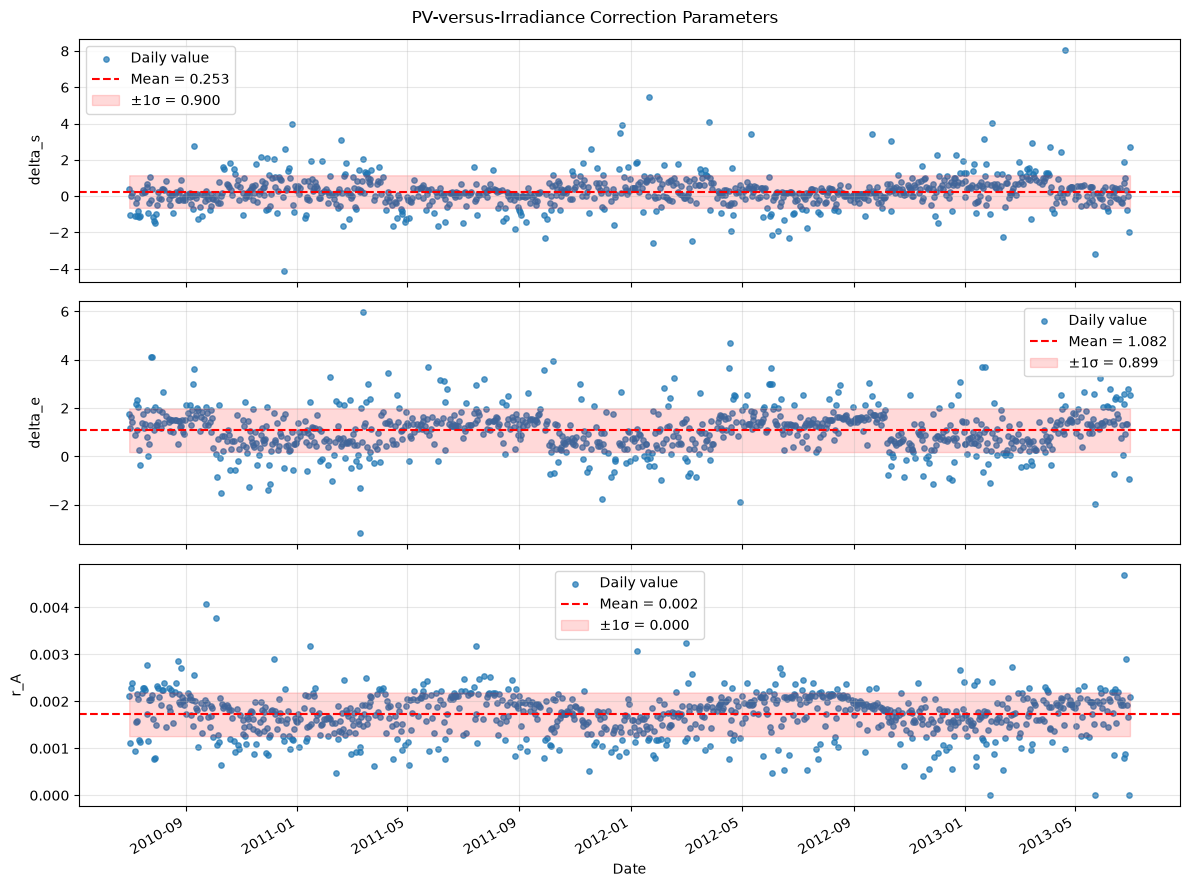

In [17]:
correction_params = ["delta_s", "delta_e", "r_A"]

fig, axes = plt.subplots(len(correction_params), 1, figsize=(12, 9), sharex=True)

for ax, param in zip(axes, correction_params):
    data = customer_1_params_df[["date", param]].dropna()
    mean_value = data[param].mean()
    std_value = data[param].std(ddof=1)

    ax.scatter(data["date"], data[param], s=15, alpha=0.7, label="Daily value")
    ax.axhline(mean_value, color="red", linestyle="--",
               label=f"Mean = {mean_value:.3f}")
    ax.fill_between(
        data["date"],
        mean_value - std_value,
        mean_value + std_value,
        color="red",
        alpha=0.15,
        label=f"±1σ = {std_value:.3f}"
    )
    ax.set_ylabel(param)
    ax.grid(True, alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Date")
fig.suptitle("PV-versus-Irradiance Correction Parameters")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

This figure shows how the three fitted correction parameters vary day-by-day across roughly 2010-2013. Each dot represents a daily value, and the dashed red line represents the average. The shaded band is one standard deviation above and below that average.

`delta_s` has a mean of 0.253 and a standard deviation of 0.9. Values are centered around zero, meaning little overall offset, but there is substantial day-to-day variation.

`delta_e` has a mean of 1.082 and a standard deviation of 0.899. Values are centered above zero, so this parameter has a positive average correction. This makes sense as the Irradiance sunset is later than the PV generation sunset. There is still considerable day-to-day variation and some outliers.

`r_A` has a mean of about 0.002 with the values tightly clustered, with some outliers.

In [18]:
mean_corrections = customer_1_params_df[["delta_s", "delta_e", "r_A"]].mean()

test_rows = []

for day in test_dates:
    day_timestamp = pd.Timestamp(day).normalize()

    ir_day = open_meteo_df[
        open_meteo_df["datetime"].dt.normalize() == day_timestamp]

    x_ir_test = (
        ir_day["datetime"].dt.hour + ir_day["datetime"].dt.minute / 60).to_numpy()
    y_ir_test = ir_day["shortwave_radiation"].to_numpy()

    ir_fit, _ = curve_fit(
        daylight_curve,
        x_ir_test,
        y_ir_test,
        p0=[y_ir_test.max(), 6.5, 20.5])

    irradiance_A, irradiance_sunrise, irradiance_sunset = ir_fit

    test_rows.append({
        "date": day_timestamp.date(),
        "irradiance_A": irradiance_A,
        "irradiance_sunrise": irradiance_sunrise,
        "irradiance_sunset": irradiance_sunset,
        "delta_s_mean": mean_corrections["delta_s"],
        "delta_e_mean": mean_corrections["delta_e"],
        "r_A_mean": mean_corrections["r_A"],
        "predicted_pv_A": irradiance_A * mean_corrections["r_A"],
        "predicted_pv_sunrise": irradiance_sunrise + mean_corrections["delta_s"],
        "predicted_pv_sunset": irradiance_sunset - mean_corrections["delta_e"],
    })

test_results_df = pd.DataFrame(test_rows).sort_values("date").reset_index(drop=True)
test_results_df


,date,irradiance_A,irradiance_sunrise,irradiance_sunset,delta_s_mean,delta_e_mean,r_A_mean,predicted_pv_A,predicted_pv_sunrise,predicted_pv_sunset
0,2010-07-05,362.405919,8.706960,17.940910,0.253434,1.081935,0.001724,0.624789,8.960394,16.858976
1,2010-07-06,477.895512,8.860702,17.799368,0.253434,1.081935,0.001724,0.823894,9.114136,16.717434
2,2010-07-14,555.079623,9.056206,18.239845,0.253434,1.081935,0.001724,0.956959,9.309640,17.157910
3,2010-07-19,289.262056,7.821588,18.639863,0.253434,1.081935,0.001724,0.498689,8.075022,17.557929
4,2010-08-02,585.549998,8.455690,18.119599,0.253434,1.081935,0.001724,1.009490,8.709123,17.037664
...,...,...,...,...,...,...,...,...,...,...
215,2013-05-26,566.445364,8.479345,18.237412,0.253434,1.081935,0.001724,0.976554,8.732778,17.155478
216,2013-06-02,127.670921,10.916085,19.479617,0.253434,1.081935,0.001724,0.220105,11.169518,18.397682
217,2013-06-04,529.092318,8.667425,18.193999,0.253434,1.081935,0.001724,0.912157,8.920858,17.112064
218,2013-06-09,415.762597,8.460933,17.659825,0.253434,1.081935,0.001724,0.716776,8.714367,16.577891


In [20]:
predicted_df = customer_test_df.copy()
predicted_df["Pgen_pred"] = np.nan

for _, r in test_results_df.iterrows():
    day = pd.Timestamp(r["date"])
    mask = predicted_df["date"] == day

    t = (
        predicted_df.loc[mask, "datetime"].dt.hour
        + predicted_df.loc[mask, "datetime"].dt.minute / 60
        + predicted_df.loc[mask, "datetime"].dt.second / 3600)

    predicted_df.loc[mask, "Pgen_pred"] = daylight_curve(
        t.to_numpy(),
        r["predicted_pv_A"],
        r["predicted_pv_sunrise"],
        r["predicted_pv_sunset"])

predicted_df = predicted_df.sort_values("datetime").reset_index(drop=True)
predicted_df.head(10)

,Customer,Generator Capacity,Postcode,datetime,Pload,Pgen,Pnet,time_of_day,date,Pgen_pred
0,1,3.78,2076,2010-07-05 00:00:00,1.453,0.0,1.453,0.0,2010-07-05,0.0
1,1,3.78,2076,2010-07-05 00:30:00,1.545,0.0,1.545,0.5,2010-07-05,0.0
2,1,3.78,2076,2010-07-05 01:00:00,1.725,0.0,1.725,1.0,2010-07-05,0.0
3,1,3.78,2076,2010-07-05 01:30:00,1.645,0.0,1.645,1.5,2010-07-05,0.0
4,1,3.78,2076,2010-07-05 02:00:00,1.316,0.0,1.316,2.0,2010-07-05,0.0
5,1,3.78,2076,2010-07-05 02:30:00,0.122,0.0,0.122,2.5,2010-07-05,0.0
6,1,3.78,2076,2010-07-05 03:00:00,1.203,0.0,1.203,3.0,2010-07-05,0.0
7,1,3.78,2076,2010-07-05 03:30:00,0.524,0.0,0.524,3.5,2010-07-05,0.0
8,1,3.78,2076,2010-07-05 04:00:00,0.136,0.0,0.136,4.0,2010-07-05,0.0
9,1,3.78,2076,2010-07-05 04:30:00,0.269,0.0,0.269,4.5,2010-07-05,0.0


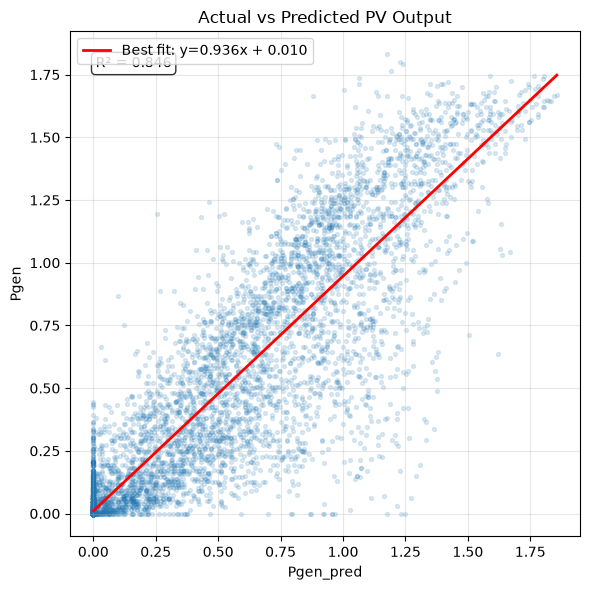

In [22]:
df = predicted_df[["Pgen", "Pgen_pred"]].dropna()
x = df["Pgen_pred"].to_numpy()
y = df["Pgen"].to_numpy()

m, b = np.polyfit(x, y, 1)
y_line = m * x + b
r2 = 1 - ((y - y_line) ** 2).sum() / ((y - y.mean()) ** 2).sum()

plt.figure(figsize=(6, 6))
plt.scatter(x, y, s=8, alpha=0.15, color="tab:blue")
plt.plot(np.sort(x), m * np.sort(x) + b, color="red", lw=2, label=f"Best fit: y={m:.3f}x + {b:.3f}")
plt.text(0.05, 0.95, f"R² = {r2:.3f}", transform=plt.gca().transAxes, va="top",
         bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8))
plt.xlabel("Pgen_pred")
plt.ylabel("Pgen")
plt.title("Actual vs Predicted PV Output")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

This scatterplot compares the predicted PV output (x-axis) to the actual PV output (y-axis). If predictions were perfect, every point would lie on the ideal line (y=x). The fitted line is $y = 0.936x + 0.010$. Its slope is close to 1 and its intercept is close to 0. The $R^2 = 0.846$ indicates that the model avvounts of 84.6% of the variation in actual output, which shows a strong overall relationship. There is a high amount of spread, showing that the model captures the general pattern, but not day-to-day variation.

We need to compare this against some baselines to see if it is actually useful. some baselines include: fixed average PV curve. Predict the average historical PV curve for every test day, ideally grouped by season or year. 
predict PV curve using the previous day's PV surve.
Fixed PV regression (without irradiance data)
Predict PV by scaling irradiance without correcting sunrise or sunset.